<a href="https://colab.research.google.com/github/jhanvimali127-spec/Logistic-regression/blob/main/Logistic_regression_%26_deployment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# read dataset
df = pd.read_csv("/content/diabetes (2).csv")
df


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

In [ ]:
df.shape

(768, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


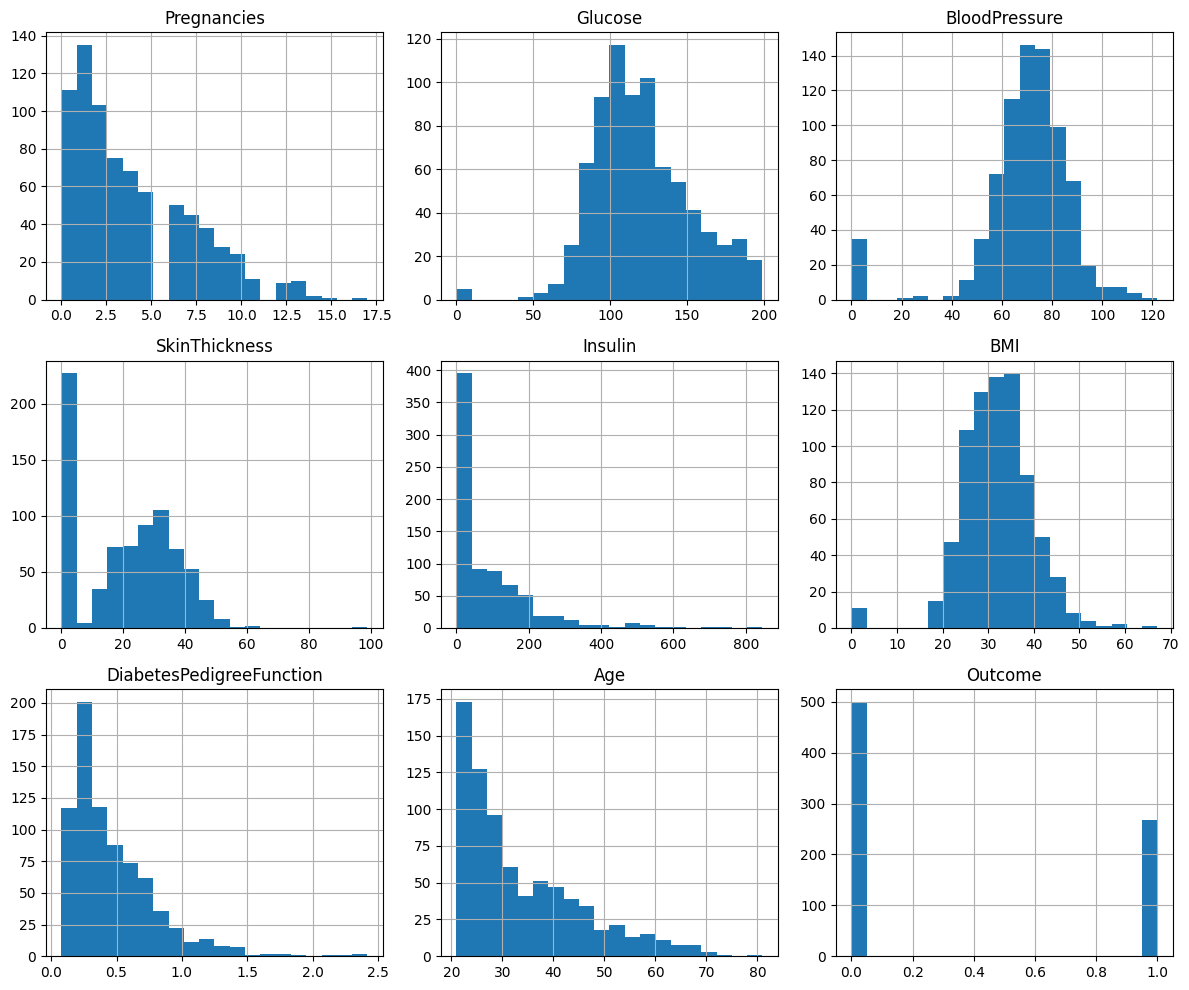

In [ ]:
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

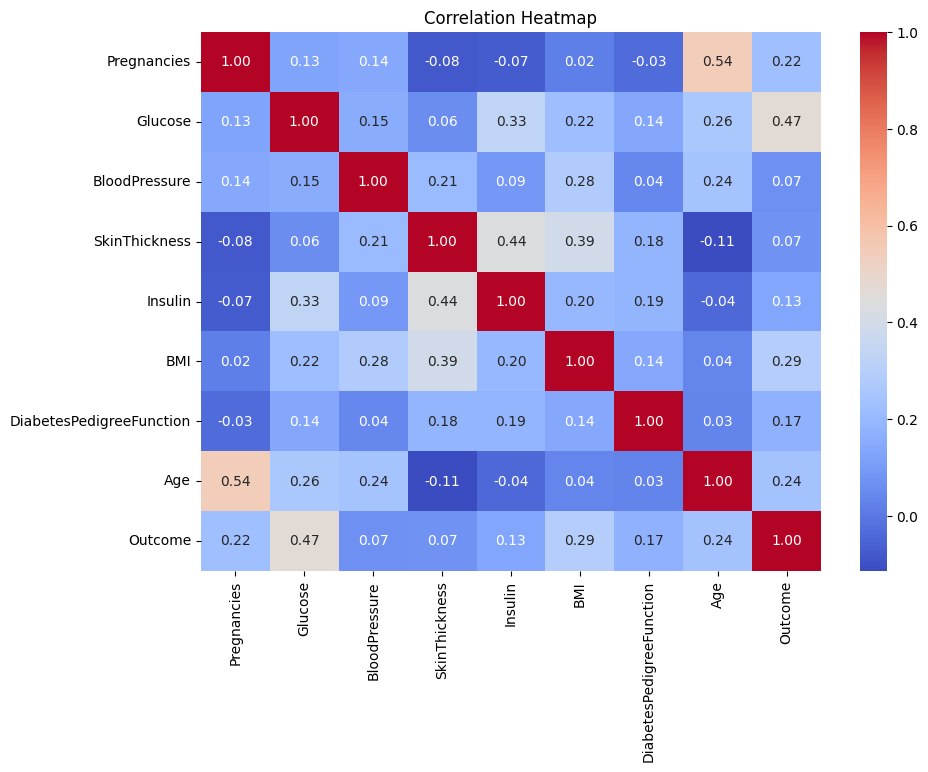

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
X = df.drop('Outcome', axis=1)

y = df['Outcome']

In [ ]:
cols = ['Glucose', 'BloodPressure',
        'SkinThickness', 'Insulin', 'BMI']

X[cols] = X[cols].replace(0, np.nan)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7077922077922078


In [ ]:
print("Precision:", precision_score(y_test, y_pred))

Precision: 0.6


In [ ]:
print("Recall:", recall_score(y_test, y_pred))

Recall: 0.5


In [ ]:
print("F1 Score:", f1_score(y_test, y_pred))

F1 Score: 0.5454545454545454


In [ ]:
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.812962962962963


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



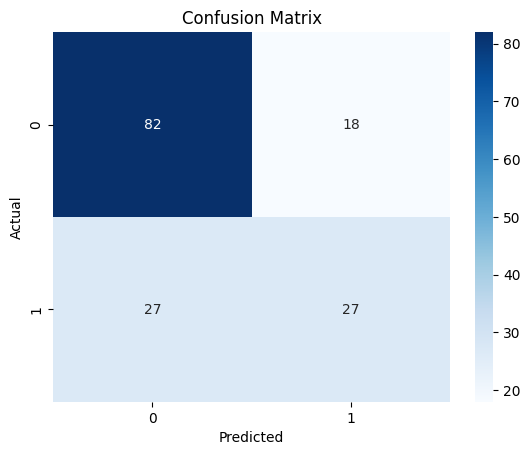

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

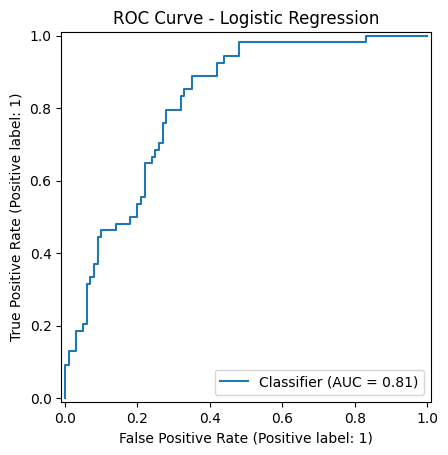

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - Logistic Regression")
plt.show()

In [ ]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", scores)

print("Mean Accuracy:", scores.mean())

Cross Validation Scores: [0.75974026 0.74675325 0.78571429 0.79738562 0.77124183]
Mean Accuracy: 0.7721670486376369


In [ ]:
lr = model.named_steps['logistic']

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_[0]
})

print(coefficients.sort_values(
    by='Coefficient',
    ascending=False
))

                    Feature  Coefficient
1                   Glucose     1.182567
5                       BMI     0.688652
0               Pregnancies     0.377446
6  DiabetesPedigreeFunction     0.233337
7                       Age     0.147794
3             SkinThickness     0.028321
2             BloodPressure    -0.044111
4                   Insulin    -0.066119


In [ ]:
new_data = pd.DataFrame([{
    'Pregnancies': 2,
    'Glucose': 120,
    'BloodPressure': 70,
    'SkinThickness': 25,
    'Insulin': 100,
    'BMI': 28.5,
    'DiabetesPedigreeFunction': 0.5,
    'Age': 30
}])

prediction = model.predict(new_data)

print("Prediction:", prediction[0])

Prediction: 0


In [ ]:
import joblib

joblib.dump(model, 'diabetes_model.pkl')

['diabetes_model.pkl']

Q1. What is the difference between Precision and Recall?
Precision:

Precision measures how many predicted positive cases are actually positive.
- It focuses on the correctness of positive predictions.
- It helps reduce False Positive (FP) results.
Formula:
\[
Precision = \frac{TP}{TP+FP}
\]

Recall:

Recall measures how many actual positive cases are correctly identified by the model.
- It focuses on identifying all actual positive cases.
- It helps reduce False Negative (FN) results.
Formula:
\[
Recall = \frac{TP}{TP+FN}
\]

Difference between Precision and Recall:
Precision	Recall
Measures correctness of positive predictions.	Measures identification of actual positive cases.
Focuses on False Positives.	Focuses on False Negatives.
High precision means fewer false positives.	High recall means fewer false negatives.
TP / (TP + FP)	TP / (TP + FN)

Example (Diabetes prediction):
- Precision: Out of 10 people predicted to have diabetes, how many actually have diabetes?
- Recall: Out of 10 people who actually have diabetes, how many did the model correctly identify?

Q2. What is Cross-validation, and why is it important in Binary Classification?
Definition:

Cross-validation is a technique used to evaluate the performance of a machine learning model by dividing the dataset into multiple parts (folds).

How does it work?

In 5-fold cross-validation:
1. The dataset is divided into 5 equal parts.
2. Four parts are used for training.
3. One part is used for testing.
4. This process is repeated 5 times, using a different part for testing each time.
5. The average performance is calculated.

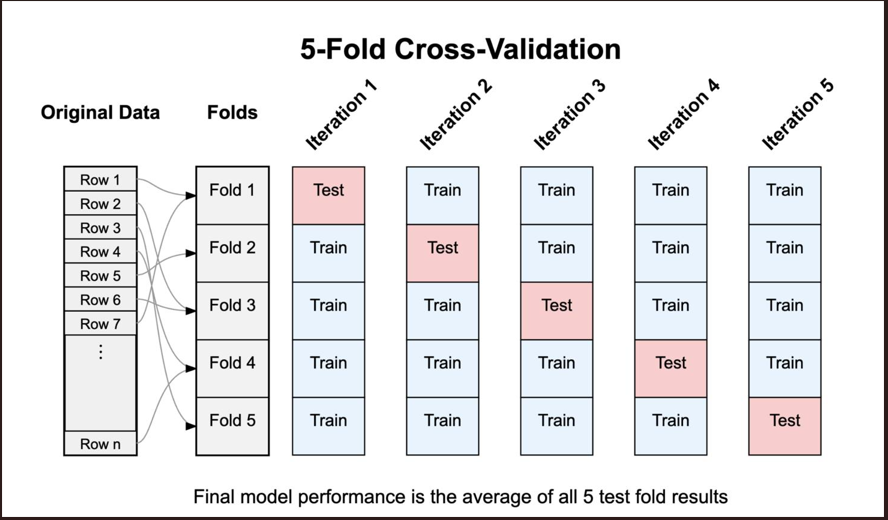

Why is it important in Binary Classification?
1. It provides a more reliable evaluation of model performance.
2. It reduces the risk of depending on a single train-test split.
3. It helps identify overfitting.
4. It checks how well the model performs on different subsets of data.
5. It helps assess model consistency.

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", scores)

print("Mean Accuracy:", scores.mean())

Cross Validation Scores: [0.75974026 0.74675325 0.78571429 0.79738562 0.77124183]
Mean Accuracy: 0.7721670486376369


Here:
- model = Logistic Regression model.
- X = Input features.
- y = Target variable (Outcome).
- cv=5 = 5-fold cross-validation.
- scores.mean() = Average accuracy.